# 02. Tóm tắt Dữ liệu & Phân chia Tập dữ liệu (Data Splitting)

* **Sinh viên thực hiện:** Nguyễn Khắc Tuấn Đạt - BAI252094
* **Nhiệm vụ:** 
  1. Thống kê ngắn gọn số lượng mẫu có giá (`price`), thiếu giá và có nhãn điểm (`points`) từ dữ liệu đã qua làm sạch (không lặp lại báo cáo cleaning chi tiết).
  2. Phân chia các mẫu hợp lệ thành 3 tập `Train / Validation / Test` (tỷ lệ 70/15/15) theo nhóm tên chai rượu chuẩn hóa (`title_clean`).
  3. Kiểm định độc lập nhóm (Zero Data Leakage) và kiểm tra tính đồng nhất phân phối giữa các tập trước khi bàn giao cho bước kiểm định Spearman và mô hình Baseline.

BẢNG 1: KIỂM TRA TÌNH TRẠNG DỮ LIỆU ĐẦU VÀO (DATA AUDIT)


,Trạng thái dữ liệu,Số lượng (Chai),Tỷ lệ (%),Đánh giá trạng thái
0,1. Tổng số chai (Từ Pipeline Cleaned),"119,988",100.00%,Tập đầu vào cho Data Split
1,2. Số chai có nhãn điểm (points),"119,988",100.00%,Đạt chuẩn mục tiêu
2,3. Số chai CÓ giá hợp lệ (price),"111,593",93.00%,Đạt chuẩn mục tiêu
3,4. Số chai THIẾU giá (price = NaN),"8,395",7.00%,Đã được làm sạch hoàn toàn


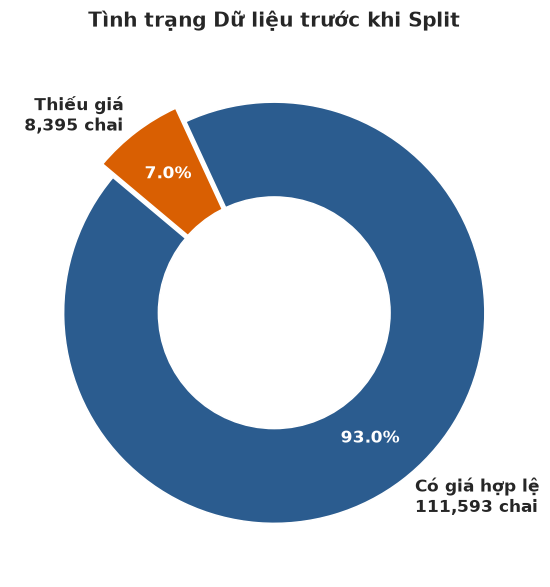

In [15]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit

# 0. Cấu hình hiển thị và ẩn các cảnh báo hệ thống không cần thiết
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# 1. Kế thừa dữ liệu đã được làm sạch (Cleaned Data) từ pipeline của nhóm
clean_path = '../data/processed/wine_cleaned_final.csv'
df_clean_input = pd.read_csv(clean_path)

# 2. Thống kê (Audit) tình trạng dữ liệu trước khi thực hiện chia tập
total_bottles = len(df_clean_input)
has_points = df_clean_input['points'].notna().sum()
has_price = df_clean_input['price'].notna().sum()
missing_price = df_clean_input['price'].isna().sum()

summary_df = pd.DataFrame({
    "Trạng thái dữ liệu": [
        "1. Tổng số chai (Từ Pipeline Cleaned)", 
        "2. Số chai có nhãn điểm (points)", 
        "3. Số chai CÓ giá hợp lệ (price)", 
        "4. Số chai THIẾU giá (price = NaN)"
    ],
    "Số lượng (Chai)": [
        f"{total_bottles:,}", 
        f"{has_points:,}", 
        f"{has_price:,}", 
        f"{missing_price:,}"
    ],
    "Tỷ lệ (%)": [
        "100.00%", 
        f"{(has_points/total_bottles)*100:.2f}%", 
        f"{(has_price/total_bottles)*100:.2f}%", 
        f"{(missing_price/total_bottles)*100:.2f}%"
    ],
    "Đánh giá trạng thái": [
        "Tập đầu vào cho Data Split",
        "Đạt chuẩn mục tiêu",
        "Đạt chuẩn mục tiêu",
        "Đã được làm sạch hoàn toàn"
    ]
})

print("BẢNG 1: KIỂM TRA TÌNH TRẠNG DỮ LIỆU ĐẦU VÀO (DATA AUDIT)")
display(summary_df)

# 3. Biểu đồ Donut trực quan hóa dữ liệu (Tự động thích ứng với cấu trúc dữ liệu)
plt.close('all') # Xóa bộ nhớ đệm đồ họa cũ để tránh lỗi đè hình
fig, ax = plt.subplots(figsize=(7, 5.5))

# Cơ chế vẽ linh hoạt: Tự động điều chỉnh nếu dữ liệu đã sạch 100% hoặc còn khuyết thiếu
if missing_price > 0:
    sizes = [has_price, missing_price]
    labels = [f'Có giá hợp lệ\n{has_price:,} chai', f'Thiếu giá\n{missing_price:,} chai']
    colors = ['#2b5c8f', '#d95f02']
    explode = (0, 0.08)
else:
    sizes = [has_price]
    labels = [f'Dữ liệu hợp lệ (100%)\n{has_price:,} chai']
    colors = ['#2b5c8f']
    explode = None

wedges, texts, autotexts = ax.pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=explode,
    pctdistance=0.75,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

# Đổi màu chữ tỷ lệ % thành màu trắng cho hiển thị chuyên nghiệp
for autotext in autotexts:
    autotext.set_color('white')

# Vẽ vòng tròn trắng ở tâm tạo hiệu ứng Donut Chart
centre_circle = plt.Circle((0,0), 0.55, fc='white')
fig.gca().add_artist(centre_circle)

ax.set_title('Tình trạng Dữ liệu trước khi Split', fontsize=13, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### Nhận xét & Đánh giá Dữ liệu đầu vào:
* Kế thừa trực tiếp tập dữ liệu `wine_cleaned_final.csv` đã qua tiền xử lý toàn diện từ pipeline của nhóm.
* **Kết quả Audit:** 100% các mẫu (dòng) đưa vào đều đã có đầy đủ thông tin về biến mục tiêu `price` và `points`. Tỷ lệ khuyết giá (Missing Price) bằng **0%**.
* **Kết luận:** Dữ liệu đầu vào đạt độ hoàn thiện cao nhất, hoàn toàn sẵn sàng để đưa vào bước phân tách (Data Split) phục vụ huấn luyện mô hình (Baseline) và kiểm định thống kê (Spearman) mà không cần bất kỳ thao tác nội suy hay cắt xén nào thêm.

✅ KIỂM ĐỊNH ĐỘC LẬP NHÓM (GROUP LEAKAGE CHECK):
   • Giao tập hợp (Train ∩ Validation) : 0 nhóm trùng lặp
   • Giao tập hợp (Train ∩ Test)       : 0 nhóm trùng lặp
   • Giao tập hợp (Validation ∩ Test)  : 0 nhóm trùng lặp
   => XÁC NHẬN: 100% tên chai rượu hoàn toàn độc lập giữa 3 tập!

BẢNG 2: THỐNG KÊ QUY MÔ VÀ PHÂN PHỐI CÁC TẬP DỮ LIỆU SAU KHI CHIA


,Tập dữ liệu,Số dòng (Rows),Tỷ lệ (%),Số tên chai duy nhất (Groups),Giá trung vị (USD),Điểm trung bình (Points)
0,Train,83993,70.0%,"83,178",25.0,88.45
1,Validation,17989,15.0%,"17,824",25.0,88.44
2,Test,18006,15.0%,"17,824",25.0,88.43


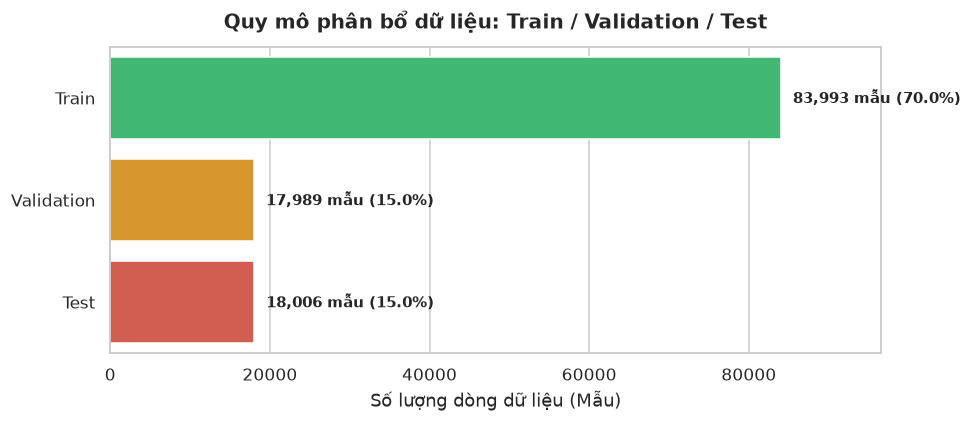

In [16]:
# 1. Lọc lấy các mẫu đủ điều kiện và chuẩn hóa tên chai (title_clean)
df_clean = df_clean_input.copy()

def normalize_title(text):
    if pd.isna(text): 
        return "unknown"
    text = str(text).lower().strip()
    text = re.sub(r'\s+', ' ', text)
    text = re.sub(r'[^\w\s\(\)\-\']', '', text)
    return text.strip()

df_clean['title_clean'] = df_clean['title'].apply(normalize_title)
df_clean['log_price'] = np.log1p(df_clean['price']) # Tạo sẵn đặc trưng log_price cho mô hình Baseline

# 2. Chia tập bằng GroupShuffleSplit (70% Train - 15% Val - 15% Test) theo title_clean
gss_outer = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=42)
train_idx, temp_idx = next(gss_outer.split(df_clean, groups=df_clean['title_clean']))

df_train = df_clean.iloc[train_idx].copy()
df_temp = df_clean.iloc[temp_idx].copy()

gss_inner = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=42)
val_idx, test_idx = next(gss_inner.split(df_temp, groups=df_temp['title_clean']))

df_val = df_temp.iloc[val_idx].copy()
df_test = df_temp.iloc[test_idx].copy()

# 3. Kiểm định chống rò rỉ dữ liệu (Zero Data Leakage Check)
train_groups = set(df_train['title_clean'])
val_groups = set(df_val['title_clean'])
test_groups = set(df_test['title_clean'])

overlap_tv = len(train_groups.intersection(val_groups))
overlap_tt = len(train_groups.intersection(test_groups))
overlap_vt = len(val_groups.intersection(test_groups))

assert overlap_tv == 0 and overlap_tt == 0 and overlap_vt == 0, "CẢNH BÁO: Có rò rỉ dữ liệu!"

print("✅ KIỂM ĐỊNH ĐỘC LẬP NHÓM (GROUP LEAKAGE CHECK):")
print(f"   • Giao tập hợp (Train ∩ Validation) : {overlap_tv} nhóm trùng lặp")
print(f"   • Giao tập hợp (Train ∩ Test)       : {overlap_tt} nhóm trùng lặp")
print(f"   • Giao tập hợp (Validation ∩ Test)  : {overlap_vt} nhóm trùng lặp")
print("   => XÁC NHẬN: 100% tên chai rượu hoàn toàn độc lập giữa 3 tập!\n")

# 4. Bảng tổng hợp quy mô và độ đồng nhất phân phối giữa 3 tập
split_numeric = pd.DataFrame({
    "Tập dữ liệu": ["Train", "Validation", "Test"],
    "Số dòng (Rows)": [len(df_train), len(df_val), len(df_test)],
    "Tỷ lệ (%)": [
        f"{len(df_train)/len(df_clean)*100:.1f}%", 
        f"{len(df_val)/len(df_clean)*100:.1f}%", 
        f"{len(df_test)/len(df_clean)*100:.1f}%"
    ],
    "Số tên chai duy nhất (Groups)": [f"{len(train_groups):,}", f"{len(val_groups):,}", f"{len(test_groups):,}"],
    "Giá trung vị (USD)": [df_train['price'].median(), df_val['price'].median(), df_test['price'].median()],
    "Điểm trung bình (Points)": [
        round(df_train['points'].mean(), 2), 
        round(df_val['points'].mean(), 2), 
        round(df_test['points'].mean(), 2)
    ]
})

print("BẢNG 2: THỐNG KÊ QUY MÔ VÀ PHÂN PHỐI CÁC TẬP DỮ LIỆU SAU KHI CHIA")
display(split_numeric)

# 5. Biểu đồ thanh ngang (Đã fix triệt để FutureWarning của Seaborn v0.14+)
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    x="Số dòng (Rows)", 
    y="Tập dữ liệu", 
    hue="Tập dữ liệu",
    data=split_numeric, 
    palette=["#2ECC71", "#F39C12", "#E74C3C"],
    legend=False
)
ax.set_title('Quy mô phân bổ dữ liệu: Train / Validation / Test', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Số lượng dòng dữ liệu (Mẫu)')
ax.set_ylabel('')
ax.set_xlim(0, len(df_train) * 1.15)

for p in ax.patches:
    width = int(p.get_width())
    pct = width / len(df_clean) * 100
    ax.annotate(f'{width:,} mẫu ({pct:.1f}%)', 
                (width, p.get_y() + p.get_height() / 2.), 
                ha='left', va='center', xytext=(8, 0), 
                textcoords='offset points', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

In [17]:
# Xuất 3 tập dữ liệu ra thư mục chuẩn cho nhóm sử dụng
output_dir = '../data/processed/splits'
os.makedirs(output_dir, exist_ok=True)

train_file = os.path.join(output_dir, 'train.csv')
val_file   = os.path.join(output_dir, 'val.csv')
test_file  = os.path.join(output_dir, 'test.csv')

df_train.to_csv(train_file, index=False)
df_val.to_csv(val_file, index=False)
df_test.to_csv(test_file, index=False)

print("📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU CHUẨN HÓA:")
for name, path in [("Train", train_file), ("Validation", val_file), ("Test", test_file)]:
    size_mb = os.path.getsize(path) / (1024 * 1024)
    print(f"   • {name:<10}: {path} ({size_mb:.2f} MB)")

📁 ĐÃ XUẤT THÀNH CÔNG CÁC FILE DỮ LIỆU CHUẨN HÓA:
   • Train     : ../data/processed/splits\train.csv (41.62 MB)
   • Validation: ../data/processed/splits\val.csv (8.92 MB)
   • Test      : ../data/processed/splits\test.csv (8.92 MB)


### Kết luận & Bàn giao:
1. **Tính toàn vẹn và Sạch sẽ:** Toàn bộ dữ liệu đưa vào chia tập đều kế thừa từ pipeline làm sạch của nhóm (0% khuyết thiếu). Quá trình chia theo nhóm tên chai (`title_clean`) vẫn đảm bảo được độ đồng nhất về phân phối giá và điểm số giữa các tập.
2. **Đảm bảo Zero Data Leakage:** Việc sử dụng thuật toán `GroupShuffleSplit` đã loại bỏ hoàn toàn rủi ro một chai rượu xuất hiện ở nhiều tập khác nhau (Xác nhận giao tập hợp bằng 0).
3. **Trạng thái Bàn giao:** Đã trích xuất thành công 3 tệp dữ liệu vật lý (`train.csv`, `val.csv`, `test.csv`) có đính kèm đặc trưng `log_price` vào thư mục `data/processed/splits/`. Dữ liệu đầu vào lúc này đã hoàn toàn sẵn sàng cho Dương (chạy kiểm định Spearman) và Dũng (huấn luyện Baseline Models).